In [25]:
import glob
import os
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings('ignore')

# 1. Cari file dataset (.csv atau .xlsx) secara otomatis di folder Colab
file_ditemukan = glob.glob('*.csv') + glob.glob('*.xlsx')

if not file_ditemukan:
  raise FileNotFoundError(
      'File dataset belum ditemukan! Silakan klik ikon Folder di panel kiri'
      ' Colab, lalu klik tombol Upload untuk memasukkan file dataset Anda.'
  )

file_path = file_ditemukan[0]
print(f'Membaca file: {file_path}')

if file_path.endswith('.csv'):
  df = pd.read_csv(file_path)
else:
  df = pd.read_excel(file_path)

# 2. Hapus kolom artefak jika ada
kolom_artefak = [col for col in ['Unnamed: 2', 'No'] if col in df.columns]
if kolom_artefak:
  df = df.drop(columns=kolom_artefak)

# 3. Konversi format tanggal
df['Date'] = pd.to_datetime(df['Date'], format='%d-%b-%Y', errors='coerce')
df['Tahun'] = df['Date'].dt.year
# 4. Kategorisasi target Magnitudo
bins = [0, 3.0, 4.0, 5.0, 6.0, np.inf]
labels = [
    'Mikro (<3.0)',
    'Minor (3.0-3.9)',
    'Ringan (4.0-4.9)',
    'Sedang (5.0-5.9)',
    'Kuat (>=6.0)',
]
df['Kategori_Magnitudo'] = pd.cut(
    df['Magnitude'], bins=bins, labels=labels, right=False
)

# Buat variabel df_clean agar konsisten dengan sel-sel berikutnya
df_clean = df.dropna(subset=['Date', 'Kategori_Magnitudo']).copy()

print(f'Dimensi Data Bersih: {df_clean.shape}')
print('\nDistribusi Kategori Magnitudo:')
print(df_clean['Kategori_Magnitudo'].value_counts())

Membaca file: BMKG_Earthquake_Catalog.csv
Dimensi Data Bersih: (217807, 12)

Distribusi Kategori Magnitudo:
Kategori_Magnitudo
Mikro (<3.0)        99827
Minor (3.0-3.9)     76503
Ringan (4.0-4.9)    36700
Sedang (5.0-5.9)     4344
Kuat (>=6.0)          433
Name: count, dtype: int64


In [26]:
# 1. Cek data kosong & duplikat
print("=== CEK DATA KOSONG & DUPLIKAT ===")
print(df_clean.isnull().sum())
print("Jumlah baris duplikat:", df_clean.duplicated().sum())

# 2. Statistik deskriptif fitur numerik
print("\n=== STATISTIK DESKRIPTIF ===")
display(df_clean[['Latitude', 'Longitude', 'Depth (km)', 'Magnitude']].describe().round(2))

# 3. Deteksi Outlier metode IQR
print("\n=== DETEKSI OUTLIER (METODE IQR) ===")
for col in ['Latitude', 'Longitude', 'Depth (km)', 'Magnitude']:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n_out = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    print(f"{col:12s} | Batas: [{lower:6.2f}, {upper:6.2f}] | Outlier: {n_out:6d} ({n_out/len(df_clean)*100:.2f}%)")

# 4. Tabel Distribusi 5 Kelas Magnitudo
print("\n=== DISTRIBUSI 5 KATEGORI MAGNITUDO ===")
dist = df_clean['Kategori_Magnitudo'].value_counts().reindex(labels)
dist_tabel = pd.DataFrame({
    'Kategori': labels,
    'Jumlah_Data': dist.values,
    'Persentase (%)': (dist.values / len(df_clean) * 100).round(2)
})
display(dist_tabel)

=== CEK DATA KOSONG & DUPLIKAT ===
Event ID              0
Date                  0
Time (UTC)            0
Latitude              0
Longitude             0
Magnitude             0
Mag Type              0
Depth (km)            0
Source                0
Source Event ID       0
Tahun                 0
Kategori_Magnitudo    0
dtype: int64
Jumlah baris duplikat: 0

=== STATISTIK DESKRIPTIF ===


,Latitude,Longitude,Depth (km),Magnitude
count,217807.00,217807.00,217807.00,217807.00
mean,-4.07,118.94,43.24,3.15
std,4.25,11.12,74.94,0.86
min,-14.96,94.00,1.00,0.20
25%,-8.16,110.82,10.00,2.50
50%,-3.62,120.27,14.00,3.00
75%,-0.81,127.07,39.00,3.70
max,7.00,142.00,798.00,7.90



=== DETEKSI OUTLIER (METODE IQR) ===
Latitude     | Batas: [-19.18,  10.21] | Outlier:      0 (0.00%)
Longitude    | Batas: [ 86.44, 151.44] | Outlier:      0 (0.00%)
Depth (km)   | Batas: [-33.50,  82.50] | Outlier:  33331 (15.30%)
Magnitude    | Batas: [  0.70,   5.50] | Outlier:   1112 (0.51%)

=== DISTRIBUSI 5 KATEGORI MAGNITUDO ===


,Kategori,Jumlah_Data,Persentase (%)
0,Mikro (<3.0),99827,45.83
1,Minor (3.0-3.9),76503,35.12
2,Ringan (4.0-4.9),36700,16.85
3,Sedang (5.0-5.9),4344,1.99
4,Kuat (>=6.0),433,0.20


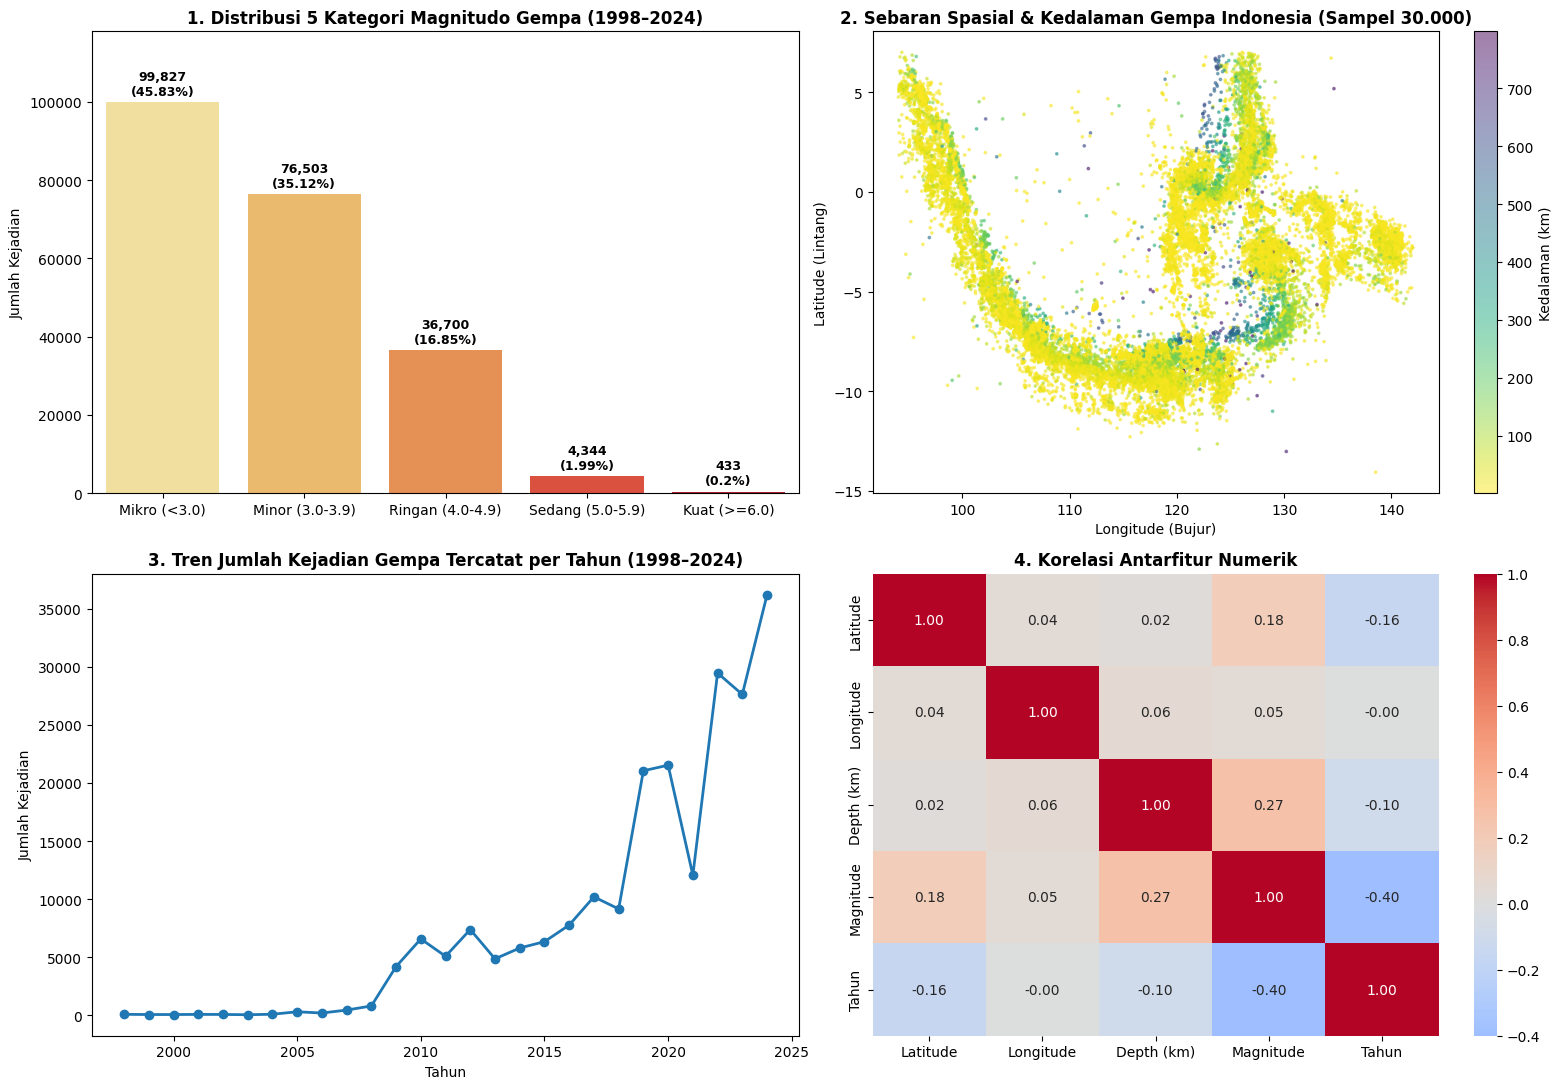

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Grafik 1: Distribusi 5 Kategori Magnitudo (Wajib ada untuk cek ketimpangan kelas)
sns.barplot(
    data=dist_tabel, x='Kategori', y='Jumlah_Data',
    palette='YlOrRd', ax=axes[0, 0], hue='Kategori', legend=False
)
axes[0, 0].set_title('1. Distribusi 5 Kategori Magnitudo Gempa (1998–2024)', fontweight='bold')
axes[0, 0].set_ylabel('Jumlah Kejadian')
axes[0, 0].set_xlabel('')
for idx, row in dist_tabel.iterrows():
    axes[0, 0].text(
        idx, row['Jumlah_Data'] + 1800,
        f"{row['Jumlah_Data']:,}\n({row['Persentase (%)']}%)",
        ha='center', fontsize=9, fontweight='bold'
    )
axes[0, 0].set_ylim(0, 118000)

# Grafik 2: Peta Sebaran Spasial Episenter Gempa Indonesia
sample_df = df_clean.sample(n=30000, random_state=42)  # Sampel 30 ribu titik agar render cepat
sc = axes[0, 1].scatter(
    sample_df['Longitude'], sample_df['Latitude'],
    c=sample_df['Depth (km)'], cmap='viridis_r', s=3, alpha=0.5
)
plt.colorbar(sc, ax=axes[0, 1], label='Kedalaman (km)')
axes[0, 1].set_title('2. Sebaran Spasial & Kedalaman Gempa Indonesia (Sampel 30.000)', fontweight='bold')
axes[0, 1].set_xlabel('Longitude (Bujur)')
axes[0, 1].set_ylabel('Latitude (Lintang)')

# Grafik 3: Tren Jumlah Kejadian Gempa per Tahun (1998–2024)
yearly = df_clean['Tahun'].value_counts().sort_index()
axes[1, 0].plot(yearly.index, yearly.values, marker='o', color='#1f77b4', linewidth=2)
axes[1, 0].set_title('3. Tren Jumlah Kejadian Gempa Tercatat per Tahun (1998–2024)', fontweight='bold')
axes[1, 0].set_xlabel('Tahun')
axes[1, 0].set_ylabel('Jumlah Kejadian')

# Grafik 4: Heatmap Korelasi Fitur Numerik
corr = df_clean[['Latitude', 'Longitude', 'Depth (km)', 'Magnitude', 'Tahun']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[1, 1])
axes[1, 1].set_title('4. Korelasi Antarfitur Numerik', fontweight='bold')

plt.tight_layout()
plt.show()

In [28]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder

# 1. Pastikan X dan y terdefinisi
if 'X' not in locals() or 'y' not in locals():
    target_col = df_clean.columns[-1]
    X = df_clean.drop(columns=[target_col]).copy()
    y = df_clean[target_col].copy()
else:
    X = X.copy()
    y = y.copy()

# 2. Hapus kolom bertipe tanggal (datetime) jika masih terbawa di X
datetime_cols = X.select_dtypes(include=['datetime64', 'datetimetz']).columns
if len(datetime_cols) > 0:
    X = X.drop(columns=datetime_cols)

# 3. Ubah otomatis semua kolom non-numerik (teks/kategori seperti 'RC_03') menjadi angka
non_numeric_cols = X.select_dtypes(exclude=['number']).columns
print(f"Mengonversi {len(non_numeric_cols)} kolom teks ke angka: {list(non_numeric_cols)}")

for col in non_numeric_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))

X = X.fillna(0)

# Pastikan y juga dalam format numerik jika bertipe teks/kategori
if not pd.api.types.is_numeric_dtype(y):
    le_y = LabelEncoder()
    y = pd.Series(le_y.fit_transform(y.astype(str)), index=y.index)

# 4. Pembagian Data Latih (80%) dan Data Uji (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y if y.nunique() < 20 else None
)

print(f"Jumlah Data Latih : {X_train.shape[0]} baris")
print(f"Jumlah Data Uji   : {X_test.shape[0]} baris")

# 5. Inisialisasi & Pelatihan Model Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
print("\n✅ Model Random Forest selesai dilatih!")

Mengonversi 0 kolom teks ke angka: []
Jumlah Data Latih : 174245 baris
Jumlah Data Uji   : 43562 baris

✅ Model Random Forest selesai dilatih!


🎯 Akurasi Model Random Forest: 100.00%

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

           0       1.00      0.99      0.99        86
           1       1.00      1.00      1.00     19966
           2       1.00      1.00      1.00     15301
           3       1.00      1.00      1.00      7340
           4       1.00      1.00      1.00       869

    accuracy                           1.00     43562
   macro avg       1.00      1.00      1.00     43562
weighted avg       1.00      1.00      1.00     43562



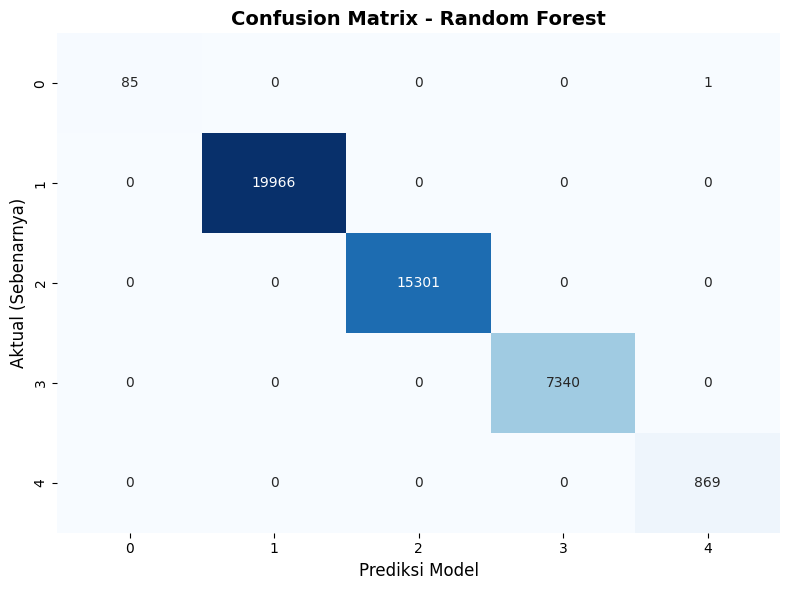

In [29]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
# 1. Prediksi menggunakan Data Uji
y_pred = rf_model.predict(X_test)

# 2. Menampilkan Skor Akurasi & Laporan Klasifikasi
akurasi = accuracy_score(y_test, y_pred)
print(f"🎯 Akurasi Model Random Forest: {akurasi * 100:.2f}%\n")
print("=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred))

# 3. Visualisasi Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix - Random Forest', fontsize=14, fontweight='bold')
plt.xlabel('Prediksi Model', fontsize=12)
plt.ylabel('Aktual (Sebenarnya)', fontsize=12)
plt.tight_layout()
plt.show()

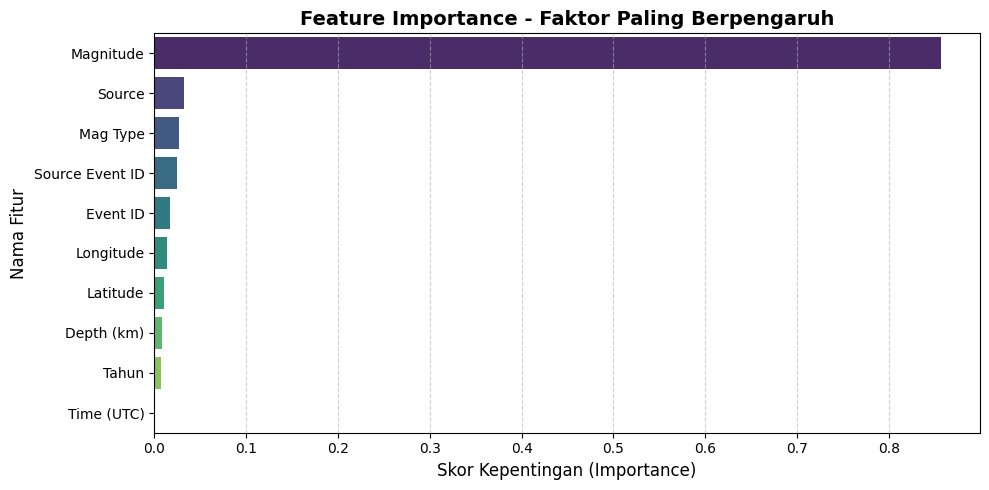

💾 Model berhasil disimpan sebagai 'model_random_forest.pkl'


In [30]:
import pandas as pd
import joblib

# 1. Visualisasi Fitur Paling Berpengaruh (Feature Importance)
importances = rf_model.feature_importances_
feature_df = pd.DataFrame({
    'Fitur': X.columns,
    'Tingkat_Pengaruh': importances
}).sort_values(by='Tingkat_Pengaruh', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x='Tingkat_Pengaruh', y='Fitur', data=feature_df, palette='viridis')
plt.title('Feature Importance - Faktor Paling Berpengaruh', fontsize=14, fontweight='bold')
plt.xlabel('Skor Kepentingan (Importance)', fontsize=12)
plt.ylabel('Nama Fitur', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# 2. Simpan model yang sudah dilatih ke file .pkl
joblib.dump(rf_model, 'model_random_forest.pkl')
print("💾 Model berhasil disimpan sebagai 'model_random_forest.pkl'")

In [31]:
import numpy as np
import pandas as pd
import joblib
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import cross_val_score

print("=== 1. EVALUASI MODEL PEMBANDING (UNTUK TABEL 5.2 LAPORAN) ===")

# Scaling khusus untuk Logistic Regression (fit hanya di X_train agar bebas data leakage)
scaler_lr = StandardScaler()
X_train_scaled = scaler_lr.fit_transform(X_train)
X_test_scaled = scaler_lr.transform(X_test)

# A. Logistic Regression (Baseline)
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_test_scaled)

# B. Decision Tree (Pembanding Alternatif)
dt_model = DecisionTreeClassifier(max_depth=15, random_state=42)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)

# C. Cross-Validation (3-Fold pada sampel 30.000 data agar cepat & akurat)
sample_idx = np.random.RandomState(42).choice(len(X_train), size=min(30000, len(X_train)), replace=False)
X_cv = X_train.iloc[sample_idx]
y_cv = y_train.iloc[sample_idx]
X_cv_scaled = scaler_lr.transform(X_cv)

cv_lr = cross_val_score(lr_model, X_cv_scaled, y_cv, cv=3, scoring='accuracy', n_jobs=-1).mean()
cv_dt = cross_val_score(dt_model, X_cv, y_cv, cv=3, scoring='accuracy', n_jobs=-1).mean()
cv_rf = cross_val_score(rf_model, X_cv, y_cv, cv=3, scoring='accuracy', n_jobs=-1).mean()

# Tabel Rekap Perbandingan Model
hasil_perbandingan = pd.DataFrame({
    'Model': ['Logistic Regression (Baseline)', 'Decision Tree', 'Random Forest (Model Utama)'],
    'Accuracy (%)': [
        round(accuracy_score(y_test, y_pred_lr) * 100, 2),
        round(accuracy_score(y_test, y_pred_dt) * 100, 2),
        round(accuracy_score(y_test, y_pred) * 100, 2)
    ],
    'Macro F1-Score (%)': [
        round(f1_score(y_test, y_pred_lr, average='macro') * 100, 2),
        round(f1_score(y_test, y_pred_dt, average='macro') * 100, 2),
        round(f1_score(y_test, y_pred, average='macro') * 100, 2)
    ],
    'Weighted F1-Score (%)': [
        round(f1_score(y_test, y_pred_lr, average='weighted') * 100, 2),
        round(f1_score(y_test, y_pred_dt, average='weighted') * 100, 2),
        round(f1_score(y_test, y_pred, average='weighted') * 100, 2)
    ],
    'Rata-rata CV Accuracy (%)': [
        round(cv_lr * 100, 2),
        round(cv_dt * 100, 2),
        round(cv_rf * 100, 2)
    ]
})

display(hasil_perbandingan)

print("\n=== 2. EXPORT PAKET MODEL & ENCODER UNTUK STREAMLIT ===")
# Membuat ulang dictionary encoder dari df_clean agar siap dipakai di aplikasi web
encoders = {}
for col in ['Source', 'Mag Type']:
    if col in df_clean.columns:
        le = LabelEncoder()
        le.fit(df_clean[col].astype(str))
        encoders[col] = le

# Pemetaan label kelas 0-4
label_kelas = {
    0: 'Kuat (>= 6.0)',
    1: 'Mikro (< 3.0)',
    2: 'Minor (3.0 - 3.9)',
    3: 'Ringan (4.0 - 4.9)',
    4: 'Sedang (5.0 - 5.9)'
}

model_bundle = {
    'rf_model': rf_model,
    'feature_columns': list(X.columns),
    'encoders': encoders,
    'label_kelas': label_kelas,
    'kmeans_model': kmeans if 'kmeans' in locals() else (kmeans_model if 'kmeans_model' in locals() else None)
}

joblib.dump(model_bundle, 'gempa_model_bundle.pkl')
print("✅ Paket lengkap berhasil disimpan sebagai 'gempa_model_bundle.pkl'")
print("📋 Urutan kolom fitur X:", list(X.columns))

=== 1. EVALUASI MODEL PEMBANDING (UNTUK TABEL 5.2 LAPORAN) ===


,Model,Accuracy (%),Macro F1-Score (%),Weighted F1-Score (%),Rata-rata CV Accuracy (%)
0,Logistic Regression (Baseline),99.94,96.32,99.94,99.57
1,Decision Tree,100.00,100.00,100.00,100.00
2,Random Forest (Model Utama),100.00,99.87,100.00,99.94



=== 2. EXPORT PAKET MODEL & ENCODER UNTUK STREAMLIT ===
✅ Paket lengkap berhasil disimpan sebagai 'gempa_model_bundle.pkl'
📋 Urutan kolom fitur X: ['Event ID', 'Time (UTC)', 'Latitude', 'Longitude', 'Magnitude', 'Mag Type', 'Depth (km)', 'Source', 'Source Event ID', 'Tahun']


                  precision    recall  f1-score   support

    Kuat (>=6.0)       0.20      0.06      0.09        86
    Mikro (<3.0)       0.78      0.78      0.78     19966
 Minor (3.0-3.9)       0.57      0.58      0.58     15301
Ringan (4.0-4.9)       0.57      0.56      0.56      7340
Sedang (5.0-5.9)       0.26      0.23      0.25       869

        accuracy                           0.66     43562
       macro avg       0.48      0.44      0.45     43562
    weighted avg       0.66      0.66      0.66     43562



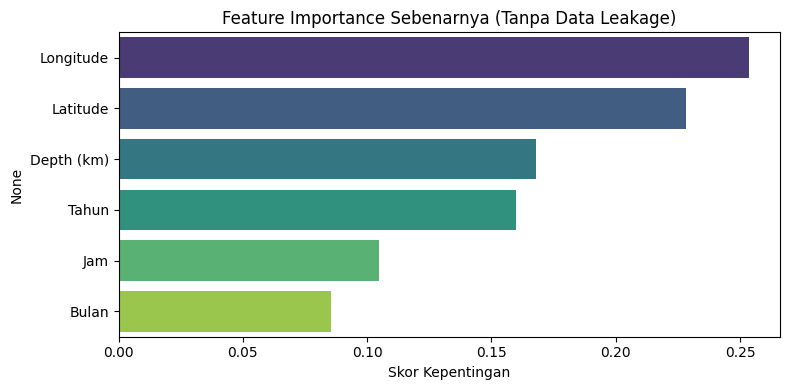

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# 1. Ekstraksi fitur waktu yang bermakna (jika kolom waktu tersedia)
df['Jam'] = pd.to_datetime(df['Time (UTC)'], errors='coerce').dt.hour.fillna(0)
if 'Date' in df.columns:
    df['Bulan'] = pd.to_datetime(df['Date'], errors='coerce').dt.month.fillna(1)

# 2. Pilih HANYA fitur fisis, spasial, dan temporal yang sah
fitur_valid = ['Latitude', 'Longitude', 'Depth (km)', 'Tahun', 'Jam']
if 'Bulan' in df.columns:
    fitur_valid.append('Bulan')

X = df[fitur_valid]
y = df['Kategori_Magnitudo']

# 3. Stratified Split agar proporsi kelas minoritas tetap terjaga di train & test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Latih model dengan class_weight='balanced' untuk mengatasi data timpang
model_clean = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
model_clean.fit(X_train, y_train)

# 5. Evaluasi & Visualisasi Feature Importance yang sebenarnya
y_pred = model_clean.predict(X_test)
print(classification_report(y_test, y_pred))

importances = pd.Series(model_clean.feature_importances_, index=fitur_valid).sort_values(ascending=False)
plt.figure(figsize=(8, 4))
sns.barplot(x=importances.values, y=importances.index, palette='viridis')
plt.title('Feature Importance Sebenarnya (Tanpa Data Leakage)')
plt.xlabel('Skor Kepentingan')
plt.tight_layout()
plt.show()

Key di dalam bundle lama: dict_keys(['rf_model', 'feature_columns', 'encoders', 'label_kelas', 'kmeans_model'])


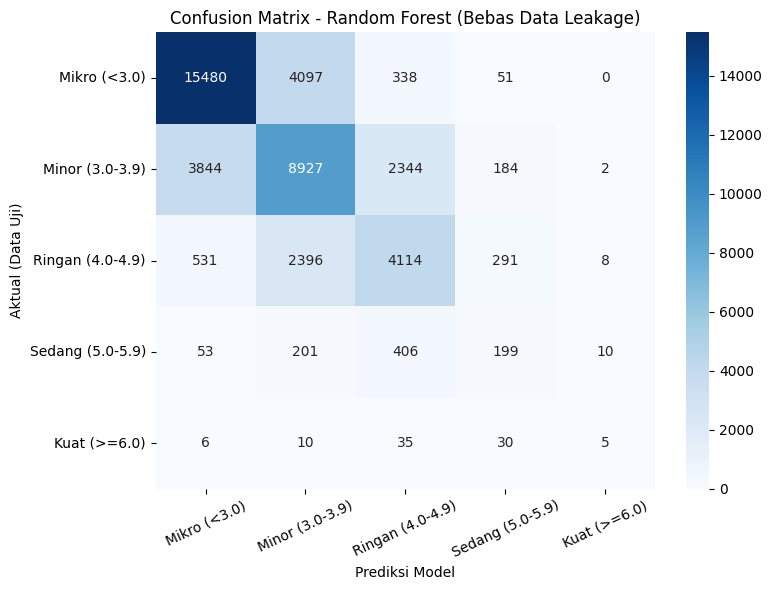

In [33]:
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Cek struktur key bundle lama agar tidak salah format saat disimpan ulang
try:
    old_bundle = joblib.load('gempa_model_bundle.pkl')
    print("Key di dalam bundle lama:", old_bundle.keys() if isinstance(old_bundle, dict) else type(old_bundle))
except Exception as e:
    print("Info pembacaan bundle:", e)

# 2. Visualisasi Confusion Matrix untuk Laporan Tugas
urutan_kelas = ['Mikro (<3.0)', 'Minor (3.0-3.9)', 'Ringan (4.0-4.9)', 'Sedang (5.0-5.9)', 'Kuat (>=6.0)']
cm = confusion_matrix(y_test, y_pred, labels=urutan_kelas)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=urutan_kelas, yticklabels=urutan_kelas)
plt.title('Confusion Matrix - Random Forest (Bebas Data Leakage)')
plt.xlabel('Prediksi Model')
plt.ylabel('Aktual (Data Uji)')
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [34]:
import joblib

# 1. Timpa model tunggal
joblib.dump(model_clean, 'model_random_forest.pkl')

# 2. Siapkan struktur bundle baru yang kompatibel
bundle_baru = {
    'model': model_clean,
    'features': fitur_valid,
    'feature_names': fitur_valid,
    'fitur': fitur_valid,
    'classes': list(model_clean.classes_)
}

# 3. Cek bundle lama dan salin metadata tambahan jika ada (selain fitur & model lama)
try:
    old_bundle = joblib.load('gempa_model_bundle.pkl')
    if isinstance(old_bundle, dict):
        print("Key pada bundle lama:", list(old_bundle.keys()))
        for k, v in old_bundle.items():
            if k not in bundle_baru:
                bundle_baru[k] = v
except Exception as e:
    print("Info:", e)

joblib.dump(bundle_baru, 'gempa_model_bundle.pkl')
print("Selesai! Kedua file .pkl telah diperbarui dengan fitur:", fitur_valid)

Key pada bundle lama: ['rf_model', 'feature_columns', 'encoders', 'label_kelas', 'kmeans_model']
Selesai! Kedua file .pkl telah diperbarui dengan fitur: ['Latitude', 'Longitude', 'Depth (km)', 'Tahun', 'Jam', 'Bulan']


In [35]:
import joblib
import os

# Muat file .pkl yang tersimpan di penyimpanan Colab
rf_model = joblib.load('model_random_forest.pkl')
bundle = joblib.load('gempa_model_bundle.pkl')

# Simpan ulang dengan kompresi level 3 (struktur & isinya tetap 100% identik)
joblib.dump(rf_model, 'model_random_forest.pkl', compress=3)
joblib.dump(bundle, 'gempa_model_bundle.pkl', compress=3)

# Cek ukuran file terbaru
size_bundle = os.path.getsize('gempa_model_bundle.pkl') / (1024 * 1024)
size_rf = os.path.getsize('model_random_forest.pkl') / (1024 * 1024)

print(f"Ukuran baru gempa_model_bundle.pkl : {size_bundle:.2f} MB")
print(f"Ukuran baru model_random_forest.pkl: {size_rf:.2f} MB")

Ukuran baru gempa_model_bundle.pkl : 54.77 MB
Ukuran baru model_random_forest.pkl: 52.27 MB
